# Parte 1 — Análise Exploratória (EDA)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from klike.data import load_raw, RAW_DATA_PATH
from klike import eda

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

df = load_raw()
df.shape


(500, 26)

## 1. Valores faltantes

Primeiro lemos o CSV **cru**, sem nenhuma conversão de tipo, para contar os nulos "de verdade". Depois comparamos com o resultado de `load_raw()`.

In [2]:
null_report = eda.missing_value_report(df_loaded=df)
null_report

,nulos_csv_cru,nulos_df_carregado,diferenca
campaign_id,0,0,0
date,0,0,0
platform,0,0,0
category,0,0,0
objective,0,0,0
target_audience_age,0,0,0
is_retargeting,0,0,0
video_duration_s,39,39,0
format,0,0,0
has_subtitle,46,46,0


Nenhuma coluna ganhou ou perdeu nulos entre o CSV cru e `load_raw()` — ou seja, **hoje** `load_raw()` preserva os nulos corretamente. Isso só é verdade porque corrigimos um bug: a versão original do `load_raw()` convertia as colunas booleanas com `.astype("bool")`, o que em pandas transforma qualquer `NaN` silenciosamente em `True`. A célula abaixo reproduz o problema diretamente na coluna crua `has_subtitle` (a única coluna booleana com nulos no dataset), comparando `.astype(bool)` com `.astype("boolean")` (dtype nullable).

In [3]:
df_subtitle_raw = pd.read_csv(RAW_DATA_PATH, usecols=["has_subtitle"])["has_subtitle"]

n_nulos = df_subtitle_raw.isna().sum()
bug_bool = df_subtitle_raw.astype(bool).value_counts(dropna=False)
fix_boolean = df_subtitle_raw.astype("boolean").value_counts(dropna=False)

print(f"nulos na coluna crua: {n_nulos}")
print("\n.astype(bool) -> nulos viram 'True' silenciosamente:")
print(bug_bool)
print("\n.astype('boolean') (nullable) -> nulos preservados como <NA>:")
print(fix_boolean)

nulos na coluna crua: 46

.astype(bool) -> nulos viram 'True' silenciosamente:
has_subtitle
True     309
False    191
Name: count, dtype: int64

.astype('boolean') (nullable) -> nulos preservados como <NA>:
has_subtitle
True     263
False    191
<NA>      46
Name: count, dtype: Int64


### Os nulos de `has_subtitle` são aleatórios?

Comparamos linhas com `has_subtitle` nulo (n=46) vs. não nulo (n=454): distribuição de `platform`, `category`, `format`, e mediana de `klike_score`, `ctr` e `engagement_rate`.

In [4]:
subtitle_analysis = eda.subtitle_missingness_analysis()

print("n por grupo:")
display(subtitle_analysis["n_por_grupo"])

print("\ndistribuição de platform (%):")
display(subtitle_analysis["distribuicao_platform"])

print("\ndistribuição de category (%):")
display(subtitle_analysis["distribuicao_category"])

print("\ndistribuição de format (%):")
display(subtitle_analysis["distribuicao_format"])

print("\nmedianas:")
display(subtitle_analysis["medianas"])

n por grupo:


,n
has_subtitle,
não nulo,454
nulo,46



distribuição de platform (%):


platform,LinkedIn,Meta,TikTok
has_subtitle,,,
nulo,19.6,45.7,34.8
não nulo,16.3,48.5,35.2



distribuição de category (%):


category,App Install,Branding,E-commerce,Lead Gen,SaaS
has_subtitle,,,,,
nulo,21.7,17.4,43.5,8.7,8.7
não nulo,15.9,12.1,31.9,19.6,20.5



distribuição de format (%):


format,horizontal,quadrado,vertical
has_subtitle,,,
nulo,21.7,26.1,52.2
não nulo,22.2,23.8,54.0



medianas:


,klike_score,ctr,engagement_rate
has_subtitle,,,
nulo,61.50,0.047,0.026
não nulo,60.35,0.065,0.021


**Conclusão (n=46 nulos vs. n=454 não nulos):** a distribuição de `platform` e `format` é quase idêntica entre os dois grupos (diferenças ≤ 3 p.p.), o que não sugere concentração por plataforma ou formato. `category` mostra uma diferença maior — o grupo com nulo tem mais `E-commerce` (43.5% vs 31.9%, +11.6 p.p.) e menos `SaaS`/`Lead Gen` (8.7% cada vs 20.5%/19.6%) — mas com apenas 46 linhas no grupo nulo essa diferença é pouco confiável (poucas observações por categoria). As medianas de `klike_score` são muito próximas (61.5 vs 60.35), mas `ctr` é visivelmente menor no grupo nulo (0.047 vs 0.065, -27.7% relativo) e `engagement_rate` levemente maior (0.026 vs 0.021). Não há um padrão fortemente concentrado em um único grupo — os nulos parecem majoritariamente **aleatórios (MAR/MCAR)**, com um sinal fraco e pouco confiável de leve associação com `category` e `ctr`, que não justifica isoladamente um tratamento diferente por grupo.

## 2. Duplicatas

In [5]:
n_linhas_duplicadas = df.duplicated().sum()
n_campaign_id_duplicados = df["campaign_id"].duplicated().sum()

print(f"linhas totalmente duplicadas: {n_linhas_duplicadas}")
print(f"campaign_id duplicado: {n_campaign_id_duplicados}")

linhas totalmente duplicadas: 0
campaign_id duplicado: 0


## 3. Valores categóricos

`value_counts` de cada coluna categórica, para procurar rótulos inconsistentes (maiúsculas/minúsculas, espaços, grafias diferentes) e valores fora do dicionário de dados em `docs/CHALLENGE.md`.

In [6]:
# dicionário de dados esperado (docs/CHALLENGE.md)
DICIONARIO_ESPERADO = {
    "platform": {"Meta", "TikTok", "LinkedIn"},
    "category": {"E-commerce", "SaaS", "App Install", "Branding", "Lead Gen"},
    "objective": {"awareness", "traffic", "conversions", "engagement", "app_install"},
    "target_audience_age": {"18-24", "25-34", "35-44", "45+"},
    "format": {"vertical", "horizontal", "quadrado"},
    "text_density": {"low", "medium", "high"},
}

for col, esperado in DICIONARIO_ESPERADO.items():
    print(f"=== {col} ===")
    print(df[col].value_counts(dropna=False))
    valores_fora = set(df[col].dropna().unique()) - esperado
    if valores_fora:
        print(f"!! valores fora do dicionário: {valores_fora}")
    else:
        print("ok: todos os valores estão no dicionário esperado")
    print()

=== platform ===
platform
Meta        241
TikTok      176
LinkedIn     83
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== category ===
category
E-commerce     165
SaaS            97
Lead Gen        93
App Install     82
Branding        63
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== objective ===
objective
conversions    165
traffic        150
engagement      79
awareness       60
app_install     46
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== target_audience_age ===
target_audience_age
25-34    143
35-44    139
18-24    137
45+       81
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== format ===
format
vertical      269
quadrado      120
horizontal    111
Name: count, dtype: int64
ok: todos os valores estão no dicionário esperado

=== text_density ===
text_density
medium    230
low       179
high       91
Name: count, dtype: int64
ok: todos os valore

## 4. Faixas válidas

In [7]:
eda.check_valid_ranges(df)

,regra,linhas_violadas,pct
0,"klike_score fora de [0, 100]",0,0.0
1,"music_voice_ratio fora de [0, 1]",0,0.0
2,"ctr fora de [0, 1]",0,0.0
3,"engagement_rate fora de [0, 1]",0,0.0
4,impressions negativo,0,0.0
5,clicks negativo,0,0.0
6,conversions negativo,0,0.0
7,spend negativo,0,0.0
8,revenue negativo,0,0.0
9,clicks > impressions,0,0.0


## 5. Consistência das métricas derivadas

Recalculamos `ctr = clicks/impressions`, `cpc = spend/clicks` e `roas = revenue/spend` e comparamos com o valor informado via **erro relativo** (`|recalculado - informado| / |informado|`). Linhas com denominador zero são excluídas do cálculo (divisão indefinida) e contadas separadamente; linhas com valor informado igual a zero também são excluídas do percentual de divergência (erro relativo indefinido), e contadas aparte.

In [8]:
metricas_derivadas = eda.check_derived_metrics(df, tol=0.01)

print("resumo (tol = 1% de erro relativo):")
display(metricas_derivadas["resumo"])

print("\nlinhas excluídas por denominador zero:")
display(metricas_derivadas["n_linhas_denominador_zero"])

print("\navg_watch_time_s > video_duration_s:")
display(metricas_derivadas["avg_watch_time_maior_que_duracao"])

resumo (tol = 1% de erro relativo):


,metrica,n_excluido_denominador_zero,n_informado_zero_excluido_do_pct,n_comparavel,n_divergente_acima_tol,pct_divergente,erro_absoluto_medio,erro_absoluto_max
0,ctr,0,0,500,16,3.20,0.000293,0.042312
1,cpc,0,0,500,6,1.20,10.820754,4790.314500
2,roas,0,76,424,27,6.37,0.031006,13.449242



linhas excluídas por denominador zero:


impressions    0
clicks         0
spend          0
Name: n_linhas, dtype: int64


avg_watch_time_s > video_duration_s:


,n_linhas,pct
0,0,0.0


## 6. Datas

In [9]:
print(f"intervalo de datas: {df['date'].min().date()} a {df['date'].max().date()}")

campanhas_mes_plataforma = (
    df.assign(mes=df["date"].dt.to_period("M").astype(str))
    .groupby(["mes", "platform"], observed=True)
    .size()
    .unstack("platform")
    .fillna(0)
    .astype(int)
)
campanhas_mes_plataforma

intervalo de datas: 2024-01-01 a 2024-12-30


platform,LinkedIn,Meta,TikTok
mes,,,
2024-01,5,24,18
2024-02,8,22,15
2024-03,7,19,8
2024-04,10,20,9
2024-05,7,20,15
2024-06,7,23,16
2024-07,7,17,13
2024-08,7,19,10
2024-09,4,20,14


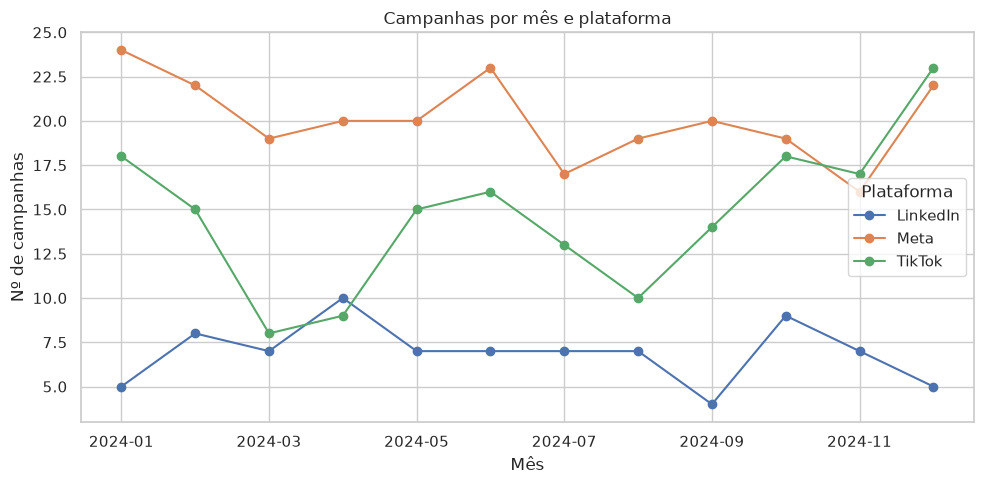

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
campanhas_mes_plataforma.plot(ax=ax, marker="o")
ax.set_title("Campanhas por mês e plataforma")
ax.set_xlabel("Mês")
ax.set_ylabel("Nº de campanhas")
ax.legend(title="Plataforma")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "campanhas_por_mes_e_plataforma.png", dpi=150)
plt.show()

## 7. Outliers

Para cada variável numérica: skewness, skewness após `log1p`, % de outliers pelo critério IQR (1.5×IQR) e um flag de distribuição log-normal. Critério de log-normal: skewness original > 1 **e** `|skewness(log1p(x))| < 0.5 * |skewness original|` (queda de pelo menos 50% na assimetria após o log).

In [11]:
NUMERIC_COLS = [
    "video_duration_s",
    "music_voice_ratio",
    "impressions",
    "clicks",
    "ctr",
    "cpc",
    "spend",
    "conversions",
    "revenue",
    "roas",
    "avg_watch_time_s",
    "engagement_rate",
    "klike_score",
]

outliers = eda.outlier_summary(df, NUMERIC_COLS)
outliers

,coluna,skewness,skewness_log1p,pct_outliers_iqr,parece_lognormal
0,video_duration_s,2.547,0.262,3.69,True
1,music_voice_ratio,0.245,-0.021,0.00,False
2,impressions,10.966,0.727,9.00,True
3,clicks,5.153,-0.210,9.80,True
4,ctr,0.434,0.385,0.00,False
5,cpc,9.894,2.745,13.98,True
6,spend,5.926,0.042,12.20,True
7,conversions,6.016,-0.004,12.20,True
8,revenue,8.317,-0.975,13.68,True
9,roas,4.390,0.576,5.40,True


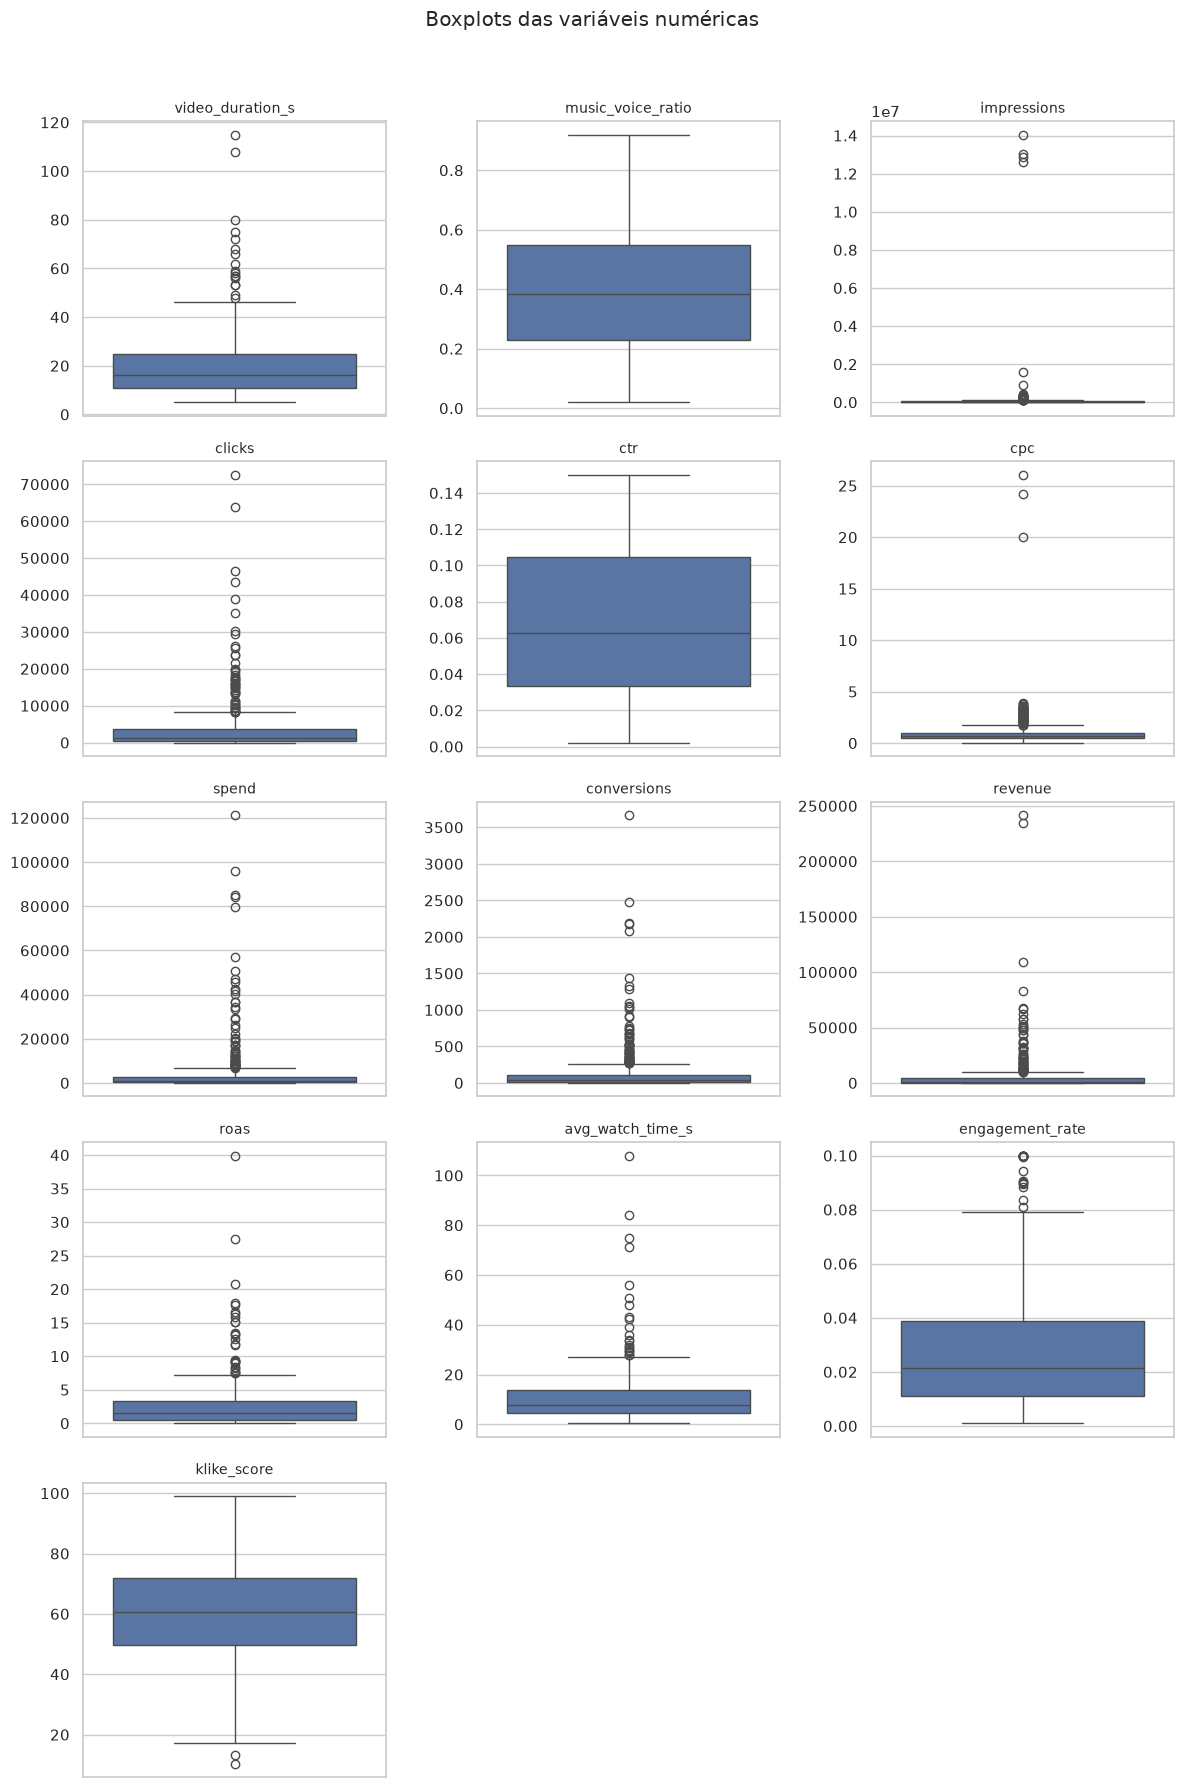

In [12]:
n_cols = 3
n_rows = -(-len(NUMERIC_COLS) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows))

for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.boxplot(y=df[col].dropna(), ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")

for ax in axes.flat[len(NUMERIC_COLS):]:
    ax.axis("off")

fig.suptitle("Boxplots das variáveis numéricas", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "boxplots_variaveis_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Tamanho dos grupos

Crosstab `platform x category` e `platform x objective`, com destaque em vermelho para células com `n < 20` (estimativas pouco confiáveis para esses subgrupos).

In [13]:
eda.group_size_table(df, "platform", "category", min_n=20)

category,App Install,Branding,E-commerce,Lead Gen,SaaS
platform,,,,,
LinkedIn,17,9,28,13,16
Meta,38,30,79,45,49
TikTok,27,24,58,35,32


In [14]:
eda.group_size_table(df, "platform", "objective", min_n=20)

objective,app_install,awareness,conversions,engagement,traffic
platform,,,,,
LinkedIn,7,10,26,10,30
Meta,21,24,84,45,67
TikTok,18,26,55,24,53


## Resumo dos achados

- **Bug corrigido:** `load_raw()` usava `.astype(bool)` nas colunas booleanas; isso convertia silenciosamente os 46 nulos de `has_subtitle` em `True`. Corrigido para `.astype("boolean")` (dtype nullable), que preserva os nulos. Os nulos de `has_subtitle` parecem majoritariamente aleatórios (n=46), com um sinal fraco e pouco confiável de leve associação com `category`/`ctr`.
- **Nulos:** além de `has_subtitle` (46), há nulos em `video_duration_s` (39), `music_voice_ratio` (38), `cpc` (28), `revenue` (25), `avg_watch_time_s` (27) e `engagement_rate` (32). Nenhuma outra coluna tem nulo.
- **Duplicatas:** nenhuma linha duplicada e nenhum `campaign_id` duplicado.
- **Categóricas:** todos os valores de `platform`, `category`, `objective`, `target_audience_age`, `format` e `text_density` estão dentro do dicionário de dados esperado — sem grafias inconsistentes.
- **Faixas válidas:** nenhuma violação em nenhuma das 11 regras (score em [0,100], ratios em [0,1], não-negativos, `clicks<=impressions`, `conversions<=clicks`).
- **Métricas derivadas:** `ctr` recalculado diverge >1% (relativo) em 16/500 linhas (3.2%); `cpc` em 6/500 (1.2%); `roas` em 27/424 linhas comparáveis (6.37%, excluindo 76 linhas com `revenue`=0, onde o erro relativo é indefinido). Não há denominador zero (`impressions`, `clicks`, `spend`) neste dataset. `avg_watch_time_s` nunca excede `video_duration_s`.
- **Datas:** campanhas de 2024-01-01 a 2024-12-30, com volume relativamente estável mês a mês entre as três plataformas.
- **Outliers/distribuição:** `impressions`, `clicks`, `cpc`, `spend`, `conversions`, `revenue`, `roas`, `avg_watch_time_s` e `video_duration_s` são fortemente assimétricos (skew > 2.5) e passam o critério de log-normalidade (log1p reduz a assimetria em mais de 50%). `engagement_rate` é assimétrico (skew 1.3) mas não "limpa" com log1p. `music_voice_ratio`, `ctr` e `klike_score` têm distribuição aproximadamente simétrica.
- **Tamanho dos grupos:** `LinkedIn` é a plataforma com menos campanhas (n=83) e fica com `n<20` em várias combinações de `category` (App Install=17, Branding=9, Lead Gen=13, SaaS=16) e `objective` (app_install=7, awareness=10, engagement=10); `TikTok×app_install` também tem n=18.

## Tabela de tratamentos propostos

Nenhum tratamento foi aplicado nesta etapa — apenas diagnóstico. Os tratamentos abaixo são propostas para a etapa de modelagem (Parte 2), a serem implementados dentro de um `Pipeline`/`ColumnTransformer` do sklearn.

| Problema | Linhas afetadas | Tratamento proposto | Justificativa |
| :--- | :--- | :--- | :--- |
| Bug: nulos de `has_subtitle` virando `True` via `.astype(bool)` | 46 | Corrigido em `load_raw()` para `.astype("boolean")`; na modelagem, imputar como categoria "desconhecido" ou pela moda, dentro do Pipeline | Nulos parecem majoritariamente aleatórios (MAR/MCAR); um valor booleano inferido errado silenciosamente é pior que um nulo explícito |
| Nulos em `video_duration_s`, `music_voice_ratio`, `cpc`, `revenue`, `avg_watch_time_s`, `engagement_rate` | 39, 38, 28, 25, 27, 32 | `SimpleImputer` (mediana) dentro de `ColumnTransformer`, nunca aplicado manualmente antes do split/CV | Regra (c) do CLAUDE.md — evitar vazamento de dados; mediana é robusta às distribuições assimétricas identificadas na seção 7 |
| Divergência entre métrica informada e recalculada (`ctr` 3.2%, `cpc` 1.2%, `roas` 6.37%) | 16 / 6 / 27 | Manter o valor informado como fonte de verdade (é o que provavelmente alimentou o `klike_score`); não remover linhas, apenas documentar a divergência | Em dataset de 500 linhas, descartar dados por pequenas divergências (prováveis arredondamentos) tem custo alto e benefício incerto |
| `revenue` informado = 0 torna erro relativo do `roas` indefinido | 76 | Excluir essas linhas apenas do cálculo do erro relativo (já feito); manter os dados originais para modelagem | Divisão por zero aqui é uma condição matemática esperada (sem receita), não um erro de dado |
| Ausência de denominador zero em `impressions`, `clicks`, `spend` | 0 (nenhuma linha neste dataset) | Nenhum tratamento necessário agora; manter guard de divisão por zero no código (feature engineering / recommender) | Não ocorre nos dados atuais, mas pode ocorrer em dados futuros reais |
| Variáveis fortemente assimétricas / log-normais (`impressions`, `clicks`, `cpc`, `spend`, `conversions`, `revenue`, `roas`, `avg_watch_time_s`, `video_duration_s`) | ver seção 7 (skew 2.5–11) | Aplicar `log1p` na etapa de feature engineering para modelos lineares; modelos baseados em árvore podem usar as variáveis originais | `log1p` reduz a assimetria em mais de 50% nessas colunas, diminuindo a influência de outliers em modelos sensíveis a escala |
| Outliers pelo critério IQR (até ~14% das linhas em `cpc`, `spend`, `conversions`, `revenue`) | ver seção 7 (0%–14%) | Não remover linhas; usar `RobustScaler` dentro do Pipeline e/ou preferir modelos robustos a outliers (árvores) | Remover 10–14% das 500 linhas é um custo alto de informação; os valores parecem extremos legítimos (campanhas de maior gasto/alcance), não erros de digitação |
| `engagement_rate` assimétrico mas não "log-normal limpo" pelo critério usado | n=500 | Avaliar `sqrt`/Box-Cox como alternativa ao `log1p`, ou manter como está e usar modelo robusto a assimetria | `log1p` só reduz a assimetria de 1.303 para 1.249 (queda < 50%), não atende ao critério de log-normalidade |
| Subgrupos pequenos (`platform x category`, `platform x objective` envolvendo `LinkedIn`/`TikTok`) | LinkedIn×App Install=17, ×Branding=9, ×Lead Gen=13, ×SaaS=16, ×app_install=7, ×awareness=10, ×engagement=10; TikTok×app_install=18 | Sempre reportar o `n` do subgrupo ao gerar recomendações contextuais (regra (e) do CLAUDE.md); considerar agregar categorias quando `n` for muito pequeno | Estimativas de efeito com `n<20` têm alta variância e podem levar o Recommendations Engine (Parte 3) a sugerir mudanças erradas |

## 9. Investigação complementar

Diagnóstico adicional sobre as divergências e nulos encontrados nas seções 1 e 5, para decidir se os erros parecem arredondamento (inofensivo) ou dados corrompidos/trocados (precisa de tratamento específico). **Nenhum dado é alterado aqui.**

### 9.1 Linhas divergentes (ctr, cpc, roas)

In [15]:
divergencias_ctr = eda.derived_metric_divergences(df, "ctr", "clicks", "impressions")
divergencias_cpc = eda.derived_metric_divergences(df, "cpc", "spend", "clicks")
divergencias_roas = eda.derived_metric_divergences(df, "roas", "revenue", "spend")

print(f"ctr: {len(divergencias_ctr)} linhas divergentes")
display(divergencias_ctr)

print(f"\ncpc: {len(divergencias_cpc)} linhas divergentes")
display(divergencias_cpc)

print(f"\nroas: {len(divergencias_roas)} linhas divergentes")
display(divergencias_roas)

ctr: 16 linhas divergentes


,campaign_id,impressions,clicks,spend,revenue,conversions,informado,recalculado,razao_informado_recalculado
231,KLK-0232,12594257,345,162.15,77.59,2,0.0295,0.000027,1076.900236
147,KLK-0148,13007321,629,339.66,0.00,2,0.0148,0.000048,306.054612
412,KLK-0413,14052761,2695,9243.85,2227.32,259,0.0374,0.000192,195.017908
257,KLK-0258,12873562,3704,2037.20,668.83,107,0.0426,0.000288,148.059865
253,KLK-0254,1962,4,2.96,0.00,0,0.0022,0.002039,1.079100
240,KLK-0241,3385,38,55.86,0.00,0,0.0115,0.011226,1.024408
67,KLK-0068,3679,27,13.50,0.00,0,0.0075,0.007339,1.021944
40,KLK-0041,1000,23,27.14,50.98,1,0.0234,0.023000,1.017391
465,KLK-0466,9222,59,53.69,NaN,0,0.0065,0.006398,1.015983
414,KLK-0415,1038,32,21.76,14.04,2,0.0313,0.030829,1.015294



cpc: 6 linhas divergentes


,campaign_id,impressions,clicks,spend,revenue,conversions,informado,recalculado,razao_informado_recalculado
258,KLK-0259,1252,20,95811.69,72.62,1,0.27,4790.584500,0.000056
108,KLK-0109,3701,205,50544.77,63.87,8,1.18,246.559854,0.004786
223,KLK-0224,117801,17670,85023.80,0.00,170,1.22,4.811760,0.253545
99,KLK-0100,13342,951,370.89,1162.54,27,20.00,0.390000,51.282051
415,KLK-0416,32532,1538,1138.12,2510.55,20,26.05,0.740000,35.202703
239,KLK-0240,135857,2825,2768.50,11936.58,88,24.17,0.980000,24.663265



roas: 27 linhas divergentes


,campaign_id,impressions,clicks,spend,revenue,conversions,informado,recalculado,razao_informado_recalculado
258,KLK-0259,1252,20,95811.69,72.62,1,13.45,0.000758,17745.348809
108,KLK-0109,3701,205,50544.77,63.87,8,0.26,0.001264,205.756070
441,KLK-0442,6309,149,567.69,26.21,3,0.05,0.046170,1.082965
53,KLK-0054,60922,4173,12936.30,718.68,125,0.06,0.055555,1.080005
427,KLK-0428,9821,763,2594.20,219.91,26,0.08,0.084770,0.943732
449,KLK-0450,11472,190,222.30,19.27,3,0.09,0.086685,1.038246
401,KLK-0402,238652,18423,41635.98,4018.65,94,0.10,0.096519,1.036069
195,KLK-0196,32041,4697,2865.17,296.33,39,0.10,0.103425,0.966885
316,KLK-0317,48515,1038,871.92,117.97,15,0.14,0.135299,1.034744
446,KLK-0447,23356,95,276.45,43.06,1,0.16,0.155761,1.027218


**Conclusão 9.1:** a maioria das divergências (12/16 em `ctr`, 26/27 em `roas`, e nenhuma em `cpc`) tem razão informado/recalculado entre 0.94 e 1.08 — compatível com **arredondamento** do valor informado (poucas casas decimais), que gera erro relativo > 1% apenas porque a métrica em si é pequena. Mas há dois padrões de **dado corrompido**, não arredondamento:

- **4 linhas com `impressions` ~12.6–14.1 milhões** (`KLK-0148`, `KLK-0232`, `KLK-0258`, `KLK-0413`), com razão informado/recalculado de 148× a 1077×. A 5ª maior `impressions` do dataset é 1.57 milhão — ou seja, essas 4 linhas estão 1–2 ordens de magnitude acima de qualquer outro valor (ver seção 9.2), sugerindo dígito(s) extra(s) em `impressions`, não um evento raro legítimo.
- **6 linhas com `cpc` muito divergente** (`KLK-0100`, `KLK-0109`, `KLK-0224`, `KLK-0240`, `KLK-0259`, `KLK-0416`), com razões entre 0.000056× e 51×. Em 3 delas (`KLK-0109`, `KLK-0224`, `KLK-0259`) o `spend` está entre os 8 maiores do dataset, mas `clicks` é baixo demais para esse gasto (ex.: `KLK-0259`: `spend`=95 811.69 para apenas 20 `clicks`), enquanto outras linhas com `spend` igualmente alto têm `cpc` perfeitamente consistente (ver seção 9.2). Isso sugere `clicks` ou `spend` trocado/corrompido nessas linhas específicas, não arredondamento.

### 9.2 Top 10 `cpc` e top 10 `impressions`

In [16]:
top_cpc = df.nlargest(10, "cpc")[["campaign_id", "cpc", "spend", "clicks"]].copy()
top_cpc["cpc_recalculado"] = (top_cpc["spend"] / top_cpc["clicks"]).round(4)

top_impressions = df.nlargest(10, "impressions")[["campaign_id", "impressions", "clicks", "ctr"]].copy()
top_impressions["ctr_recalculado"] = (top_impressions["clicks"] / top_impressions["impressions"]).round(6)

print("top 10 cpc informado:")
display(top_cpc)

print("\ntop 10 impressions:")
display(top_impressions)

top 10 cpc informado:


,campaign_id,cpc,spend,clicks,cpc_recalculado
415,KLK-0416,26.05,1138.12,1538,0.74
239,KLK-0240,24.17,2768.50,2825,0.98
99,KLK-0100,20.00,370.89,951,0.39
485,KLK-0486,3.94,3707.54,941,3.94
441,KLK-0442,3.81,567.69,149,3.81
11,KLK-0012,3.78,20521.62,5429,3.78
69,KLK-0070,3.63,188.76,52,3.63
140,KLK-0141,3.57,4494.63,1259,3.57
1,KLK-0002,3.54,1745.22,493,3.54
242,KLK-0243,3.47,8081.63,2329,3.47



top 10 impressions:


,campaign_id,impressions,clicks,ctr,ctr_recalculado
412,KLK-0413,14052761,2695,0.0374,0.000192
147,KLK-0148,13007321,629,0.0148,0.000048
257,KLK-0258,12873562,3704,0.0426,0.000288
231,KLK-0232,12594257,345,0.0295,0.000027
434,KLK-0435,1570242,72545,0.0462,0.046200
286,KLK-0287,903286,43448,0.0481,0.048100
486,KLK-0487,426466,63969,0.1500,0.149998
88,KLK-0089,360448,19031,0.0528,0.052798
21,KLK-0022,334928,17617,0.0526,0.052599
396,KLK-0397,328052,13581,0.0414,0.041399


### 9.3 Reconstrução exata de nulos (`cpc` e `revenue`)

In [17]:
cpc_null = eda.reconstructable_cpc_nulls(df)
print(f"cpc nulo: {len(cpc_null)} linhas")
print(f"spend disponível: {cpc_null['spend_disponivel'].sum()}")
print(f"clicks disponível: {cpc_null['clicks_disponivel'].sum()}")
print(f"clicks == 0 entre os nulos: {cpc_null['clicks_igual_zero'].sum()}")
print(f"reconstruível via spend/clicks: {cpc_null['reconstruivel'].sum()} / {len(cpc_null)}")
display(cpc_null)

cpc nulo: 28 linhas
spend disponível: 28
clicks disponível: 28
clicks == 0 entre os nulos: 0
reconstruível via spend/clicks: 28 / 28


,campaign_id,spend,clicks,spend_disponivel,clicks_disponivel,clicks_igual_zero,reconstruivel,cpc_reconstruido
6,KLK-0007,2158.55,1877,True,True,False,True,1.15
75,KLK-0076,171.70,505,True,True,False,True,0.34
78,KLK-0079,2915.50,8330,True,True,False,True,0.35
110,KLK-0111,3319.36,3608,True,True,False,True,0.92
118,KLK-0119,1234.63,331,True,True,False,True,3.73
130,KLK-0131,121.41,171,True,True,False,True,0.71
145,KLK-0146,1330.00,2375,True,True,False,True,0.56
161,KLK-0162,170.88,534,True,True,False,True,0.32
185,KLK-0186,1052.10,2338,True,True,False,True,0.45
199,KLK-0200,8969.52,16017,True,True,False,True,0.56


In [18]:
rev_null = eda.reconstructable_revenue_nulls(df)
print(f"revenue nulo: {len(rev_null)} linhas")
print(f"roas disponível: {rev_null['roas_disponivel'].sum()}")
print(f"spend disponível: {rev_null['spend_disponivel'].sum()}")
print(f"reconstruível via roas*spend: {rev_null['reconstruivel'].sum()} / {len(rev_null)}")
print(f"com roas confiável (dentro do IQR e != 0): {rev_null['roas_confiavel'].sum()} / {len(rev_null)}")
display(rev_null)

revenue nulo: 25 linhas
roas disponível: 25
spend disponível: 25
reconstruível via roas*spend: 25 / 25
com roas confiável (dentro do IQR e != 0): 19 / 25


,campaign_id,roas,spend,conversions,roas_disponivel,spend_disponivel,roas_fora_iqr,roas_igual_zero,roas_confiavel,reconstruivel,revenue_reconstruido
1,KLK-0002,0.16,1745.22,34,True,True,False,False,True,True,279.2352
30,KLK-0031,3.25,3880.20,268,True,True,False,False,True,True,12610.6500
58,KLK-0059,0.00,237.12,3,True,True,False,True,False,True,0.0000
109,KLK-0110,0.00,1478.23,5,True,True,False,True,False,True,0.0000
144,KLK-0145,1.48,252.63,6,True,True,False,False,True,True,373.8924
158,KLK-0159,1.24,1517.67,216,True,True,False,False,True,True,1881.9108
182,KLK-0183,0.47,308.58,4,True,True,False,False,True,True,145.0326
187,KLK-0188,4.31,4214.39,355,True,True,False,False,True,True,18164.0209
193,KLK-0194,2.19,185.40,15,True,True,False,False,True,True,406.0260
202,KLK-0203,3.16,253.84,6,True,True,False,False,True,True,802.1344


**Conclusão 9.3:** `cpc` é 100% reconstruível (28/28) via `spend/clicks` — `spend` e `clicks` estão disponíveis e nenhuma linha tem `clicks`=0. Para `revenue`, as 25 linhas têm `roas` e `spend` disponíveis (25/25 "reconstruível" no sentido técnico de `roas*spend` ser computável), mas o `roas` é pouco confiável em 6 delas: 4 com `roas`=0 (`KLK-0059`, `KLK-0110`, `KLK-0280`, `KLK-0466` — em 2 delas, `KLK-0280` e `KLK-0466`, `conversions`=0 também, o que é consistente; nas outras 2, `conversions`=3 e 5, o que é inconsistente com receita zero) e 2 com `roas` acima do limite IQR geral (`KLK-0358`=8.17, `KLK-0386`=11.61 — ainda dentro do máximo observado de 39.92, prováveis outliers legítimos, não corrompidos). Ou seja, **19/25 (76%) são reconstruíveis com confiança direta**; as outras 6 precisam de critério manual (ex.: usar a mediana de `revenue` do grupo platform×category em vez de `roas*spend`).

### 9.4 `revenue == 0` por `objective` e por `category`

In [19]:
print("revenue == 0 por objective:")
display(eda.revenue_zero_breakdown(df, "objective"))

print("\nrevenue == 0 por category:")
display(eda.revenue_zero_breakdown(df, "category"))

revenue == 0 por objective:


,revenue>0,revenue==0,total,pct_zero
objective,,,,
app_install,44,0,44,0.0
awareness,24,33,57,57.9
conversions,152,4,156,2.6
engagement,46,31,77,40.3
traffic,137,4,141,2.8



revenue == 0 por category:


,revenue>0,revenue==0,total,pct_zero
category,,,,
App Install,76,0,76,0.0
Branding,0,61,61,100.0
E-commerce,154,2,156,1.3
Lead Gen,88,3,91,3.3
SaaS,85,6,91,6.6


**Conclusão 9.4:** sim, `revenue == 0` se concentra fortemente em `objective` ∈ {`awareness` (33/57 = 57.9%), `engagement` (31/77 = 40.3%)} e quase exclusivamente em `category` = `Branding` (61/61 = **100.0%**). Nos demais objetivos/categorias a taxa é baixa (2.4%–6.6%). Isso é esperado do ponto de vista de negócio — campanhas de `awareness`/`engagement` e da categoria `Branding` não visam conversão direta, então não geram receita atribuída — e não indica erro de dado.

### 9.5 Sobreposição de nulos entre colunas

In [20]:
COLUNAS_COM_NULO = [
    "has_subtitle",
    "video_duration_s",
    "music_voice_ratio",
    "cpc",
    "revenue",
    "avg_watch_time_s",
    "engagement_rate",
]

cooc = eda.null_cooccurrence_matrix(df, COLUNAS_COM_NULO)

print("matriz observada (contagem de linhas nulas simultaneamente; diagonal = total de nulos na coluna):")
display(cooc["observado"])

print("\nesperado sob independência (nA*nB/n):")
display(cooc["esperado_sob_independencia"])

print("\nrazão observado/esperado:")
display(cooc["razao_observado_esperado"])

print("\nnº de colunas nulas simultaneamente, por linha:")
display(cooc["nulos_por_linha"])

matriz observada (contagem de linhas nulas simultaneamente; diagonal = total de nulos na coluna):


,has_subtitle,video_duration_s,music_voice_ratio,cpc,revenue,avg_watch_time_s,engagement_rate
has_subtitle,46,4,4,2,2,2,4
video_duration_s,4,39,2,1,3,3,3
music_voice_ratio,4,2,38,1,2,4,6
cpc,2,1,1,28,1,0,0
revenue,2,3,2,1,25,1,1
avg_watch_time_s,2,3,4,0,1,27,3
engagement_rate,4,3,6,0,1,3,32



esperado sob independência (nA*nB/n):


,has_subtitle,video_duration_s,music_voice_ratio,cpc,revenue,avg_watch_time_s,engagement_rate
has_subtitle,4.23,3.59,3.50,2.58,2.30,2.48,2.94
video_duration_s,3.59,3.04,2.96,2.18,1.95,2.11,2.50
music_voice_ratio,3.50,2.96,2.89,2.13,1.90,2.05,2.43
cpc,2.58,2.18,2.13,1.57,1.40,1.51,1.79
revenue,2.30,1.95,1.90,1.40,1.25,1.35,1.60
avg_watch_time_s,2.48,2.11,2.05,1.51,1.35,1.46,1.73
engagement_rate,2.94,2.50,2.43,1.79,1.60,1.73,2.05



razão observado/esperado:


,has_subtitle,video_duration_s,music_voice_ratio,cpc,revenue,avg_watch_time_s,engagement_rate
has_subtitle,10.87,1.11,1.14,0.78,0.87,0.81,1.36
video_duration_s,1.11,12.82,0.67,0.46,1.54,1.42,1.20
music_voice_ratio,1.14,0.67,13.16,0.47,1.05,1.95,2.47
cpc,0.78,0.46,0.47,17.86,0.71,0.00,0.00
revenue,0.87,1.54,1.05,0.71,20.00,0.74,0.62
avg_watch_time_s,0.81,1.42,1.95,0.00,0.74,18.52,1.74
engagement_rate,1.36,1.20,2.47,0.00,0.62,1.74,15.62



nº de colunas nulas simultaneamente, por linha:


,n_linhas
0,309
1,152
2,34
3,5


**Conclusão 9.5:** a maior parte das linhas (309/500 = 61.8%) não tem nenhum nulo entre essas 7 colunas, 152/500 (30.4%) têm exatamente 1, 34/500 (6.8%) têm 2, e apenas 5/500 (1.0%) têm 3 — nenhuma linha tem 4 ou mais. A razão observado/esperado (sob independência) fica entre 0 e 2.47 para todos os pares fora da diagonal, com contagens absolutas pequenas (máximo 6 linhas, para `music_voice_ratio` × `engagement_rate`, esperado 2.43). Não há nenhum par com sobreposição sistemática e expressiva — a missingness entre as colunas parece **independente** (cada coluna tem seu próprio mecanismo aleatório de nulo), reforçando a conclusão da seção 1 de que os nulos são majoritariamente MCAR/MAR e podem ser imputados coluna a coluna, sem precisar de um tratamento conjunto.

## 10. Decisões finais de tratamento — `clean()`

Aplicamos as correções determinísticas decididas a partir da investigação da seção 9 (`klike.data.clean()`, ver docstring para a lista completa e a justificativa de cada uma). A partir daqui, todas as análises usam `load_clean()`. A imputação estatística de nulos remanescentes (`has_subtitle`, `video_duration_s`, `music_voice_ratio`, `avg_watch_time_s`, `engagement_rate`) fica para o Pipeline de modelagem (Parte 2).

In [21]:
from klike.data import load_clean, CLEAN_DATA_PATH

df_antes = df.copy()
df_limpo = load_clean()

print(f"linhas corrigidas: {df_limpo['linha_corrigida'].sum()} / {len(df_limpo)}")
df_limpo["linha_corrigida"].value_counts()

linhas corrigidas: 62 / 500


linha_corrigida
False    438
True      62
Name: count, dtype: int64

In [22]:
corrigidas = df_limpo.loc[df_limpo["linha_corrigida"], "campaign_id"]

cols_comparar = ["campaign_id", "impressions", "spend", "revenue", "ctr", "cpc", "roas"]
antes = df_antes.set_index("campaign_id").loc[corrigidas, cols_comparar[1:]].add_suffix("_antes")
depois = (
    df_limpo.set_index("campaign_id")
    .loc[corrigidas, cols_comparar[1:] + ["correcao_aplicada"]]
    .add_suffix("_depois")
)

comparacao = pd.concat([antes, depois], axis=1).reset_index()
comparacao

,campaign_id,impressions_antes,spend_antes,revenue_antes,ctr_antes,cpc_antes,roas_antes,impressions_depois,spend_depois,revenue_depois,ctr_depois,cpc_depois,roas_depois,correcao_aplicada_depois
0,KLK-0002,7433,1745.22,NaN,0.0664,3.54,0.16,7433,1745.22,279.2352,0.066326,3.54,0.160000,revenue reconstruído = roas_informado * spend
1,KLK-0007,12960,2158.55,2233.56,0.1449,NaN,1.03,12960,2158.55,2233.5600,0.144830,1.15,1.034750,cpc reconstruído = spend / clicks (estava nulo)
2,KLK-0031,78620,3880.20,NaN,0.0851,0.58,3.25,78620,3880.20,12610.6500,0.085093,0.58,3.250000,revenue reconstruído = roas_informado * spend
3,KLK-0059,11848,237.12,NaN,0.0193,1.04,0.00,11848,237.12,0.0000,0.019244,1.04,0.000000,revenue reconstruído = roas_informado * spend;...
4,KLK-0076,15053,171.70,1201.05,0.0336,NaN,7.00,15053,171.70,1201.0500,0.033548,0.34,6.995050,cpc reconstruído = spend / clicks (estava nulo)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,KLK-0465,2311,872.34,303.54,0.0874,NaN,0.35,2311,872.34,303.5400,0.086975,4.34,0.347961,cpc reconstruído = spend / clicks (estava nulo)
58,KLK-0466,9222,53.69,NaN,0.0065,0.91,0.00,9222,53.69,0.0000,0.006398,0.91,0.000000,revenue reconstruído = roas_informado * spend
59,KLK-0484,151431,9120.71,47347.48,0.0899,NaN,5.19,151431,9120.71,47347.4800,0.089896,0.67,5.191206,cpc reconstruído = spend / clicks (estava nulo)
60,KLK-0486,10994,3707.54,NaN,0.0856,3.94,0.95,10994,3707.54,3522.1630,0.085592,3.94,0.950000,revenue reconstruído = roas_informado * spend


### 10.1 Checagem da triangulação para `spend` corrigido (`KLK-0259`, `KLK-0109`)

Para essas duas linhas, `spend_corrigido = cpc_informado * clicks`. Verificamos que `revenue_informado / spend_corrigido ≈ roas_informado` (tolerância 2%) — se bater, confirma que `cpc` e `roas` informados eram consistentes entre si e só `spend` estava corrompido. `KLK-0224` tem `revenue`=0, então essa checagem é indefinida (0/spend = 0 = roas informado, independente do valor de `spend`) — não serve como confirmação independente, e fica registrado como limitação.

In [23]:
checagem_rows = []
for cid in ["KLK-0259", "KLK-0109", "KLK-0224"]:
    raw_row = df_antes.loc[df_antes["campaign_id"] == cid].iloc[0]
    clean_row = df_limpo.loc[df_limpo["campaign_id"] == cid].iloc[0]

    spend_corrigido = clean_row["spend"]
    roas_informado = raw_row["roas"]
    revenue_informado = raw_row["revenue"]
    checagem = revenue_informado / spend_corrigido
    erro_relativo = abs(checagem - roas_informado) / roas_informado if roas_informado != 0 else np.nan

    checagem_rows.append(
        {
            "campaign_id": cid,
            "spend_bruto": raw_row["spend"],
            "spend_corrigido": spend_corrigido,
            "revenue_informado": revenue_informado,
            "roas_informado": roas_informado,
            "revenue_informado/spend_corrigido": round(checagem, 6),
            "erro_relativo_vs_roas_informado": round(erro_relativo, 6) if erro_relativo == erro_relativo else "indefinido (0/0)",
            "dentro_de_2%": bool(erro_relativo <= 0.02) if erro_relativo == erro_relativo else "não aplicável",
        }
    )

pd.DataFrame(checagem_rows)

,campaign_id,spend_bruto,spend_corrigido,revenue_informado,roas_informado,revenue_informado/spend_corrigido,erro_relativo_vs_roas_informado,dentro_de_2%
0,KLK-0259,95811.69,5.4,72.62,13.45,13.448148,0.000138,True
1,KLK-0109,50544.77,241.9,63.87,0.26,0.264035,0.015518,True
2,KLK-0224,85023.80,21557.4,0.00,0.00,0.000000,indefinido (0/0),não aplicável


### 10.2 Validação: `check_valid_ranges` e `check_derived_metrics` no dado limpo

Esperado: 0 violações de faixa e 0 divergências > 1% nas métricas derivadas (já que `ctr`, `cpc` e `roas` foram recalculados a partir das colunas brutas corrigidas).

In [24]:
print("check_valid_ranges (dado limpo):")
display(eda.check_valid_ranges(df_limpo))

print("\ncheck_derived_metrics (dado limpo):")
dm_limpo = eda.check_derived_metrics(df_limpo, tol=0.01)
display(dm_limpo["resumo"])

print("\nnulos remanescentes (não tratados nesta etapa):")
display(df_limpo.isna().sum()[df_limpo.isna().sum() > 0])

print(f"\nshape final: {df_limpo.shape}")

check_valid_ranges (dado limpo):


,regra,linhas_violadas,pct
0,"klike_score fora de [0, 100]",0,0.0
1,"music_voice_ratio fora de [0, 1]",0,0.0
2,"ctr fora de [0, 1]",0,0.0
3,"engagement_rate fora de [0, 1]",0,0.0
4,impressions negativo,0,0.0
5,clicks negativo,0,0.0
6,conversions negativo,0,0.0
7,spend negativo,0,0.0
8,revenue negativo,0,0.0
9,clicks > impressions,0,0.0



check_derived_metrics (dado limpo):


,metrica,n_excluido_denominador_zero,n_informado_zero_excluido_do_pct,n_comparavel,n_divergente_acima_tol,pct_divergente,erro_absoluto_medio,erro_absoluto_max
0,ctr,0,0,500,0,0.0,0.0,0.0
1,cpc,0,0,500,0,0.0,0.0,0.0
2,roas,0,76,424,0,0.0,0.0,0.0



nulos remanescentes (não tratados nesta etapa):


video_duration_s     39
has_subtitle         46
music_voice_ratio    38
avg_watch_time_s     27
engagement_rate      32
dtype: int64


shape final: (500, 28)


In [25]:
CLEAN_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df_limpo.to_parquet(CLEAN_DATA_PATH, index=False)
print(f"salvo em {CLEAN_DATA_PATH.relative_to(PROJECT_ROOT)}")

salvo em data/processed/klike_clean.parquet


# Parte 1 — Insights

Respostas às perguntas 2 (atributos x performance), 3 (padrões por plataforma) e 4 (visualizações) do desafio. **Sempre `load_clean()`** a partir daqui. Linguagem: sempre "associado a", nunca "causa"/"aumenta" — dados observacionais.

## 11. Setup: dados, faixas e métricas derivadas

In [26]:
df = load_clean()
df = eda.discretize_duration(df)
df = eda.discretize_music_voice(df)
df = eda.add_derived_metrics(df)
df_roas = df[eda.roas_subset_mask(df)]

print(f"df: {df.shape}, df_roas (subconjunto para roas): {df_roas.shape}")

df: (500, 32), df_roas (subconjunto para roas): (361, 32)


### 11.1 Faixas de `video_duration_s` e `music_voice_ratio`

`video_duration_s` em 4 faixas (<=15s, 15-30s, 30-60s, >60s) deixava `>60s` com n=8 (<20, amostra insuficiente). **Ajustado para 3 faixas**, unindo 30-60s e >60s em `>30s`.

In [27]:
print("video_duration_bin:")
print(df["video_duration_bin"].value_counts(dropna=False).sort_index())
print("\nmusic_voice_bin:")
print(df["music_voice_bin"].value_counts(dropna=False).sort_index())

video_duration_bin:
video_duration_bin
<=15s     228
15-30s    177
>30s       56
NaN        39
Name: count, dtype: int64

music_voice_bin:
music_voice_bin
mais_voz       186
equilibrado    227
mais_musica     49
NaN             38
Name: count, dtype: int64


### 11.2 Subconjunto de `roas`

Análises de `roas` usam só campanhas fora da `category` `Branding` (zero estrutural, ver `docs/eda_qualidade.md` seção 4) e com `objective` em {`conversions`, `traffic`, `app_install`} (decisão registrada na mesma seção).

In [28]:
print(f"n do subconjunto de roas: {len(df_roas)} / {len(df)}")
print("\npor category:")
print(df_roas["category"].value_counts())
print("\npor objective:")
print(df_roas["objective"].value_counts())

n do subconjunto de roas: 361 / 500

por category:
category
E-commerce     165
App Install     82
SaaS            70
Lead Gen        44
Branding         0
Name: count, dtype: int64

por objective:


objective
conversions    165
traffic        150
app_install     46
awareness        0
engagement       0
Name: count, dtype: int64


### 11.3 Atributo x métrica (efeito geral)

**Metodologia:**
- Mediana de cada nível (não média — variáveis assimétricas, seção 1.7), com o `n` de cada grupo.
- Efeito vs. um nível de referência fixo por atributo: binários → referência = "sem"; `format` → `vertical` (mais frequente); `text_density` → `low`; `video_duration_bin` → `<=15s`; `music_voice_bin` → `mais_voz`. Todos ordinais/convencionais de negócio.
- Para a maioria das métricas, o efeito é o **lift relativo da mediana (%)**: `(mediana_grupo/mediana_referência - 1) * 100`. Para `klike_score`, o efeito é a **diferença absoluta de medianas em pontos** (um score não é uma razão; diferença em pontos é mais interpretável).
- IC95% por **bootstrap de duas amostras independentes** (1000 reamostragens, `random_state=42`): o grupo de referência e o grupo comparado são reamostrados **separadamente**, cada um com o próprio `n`, com reposição (ver docstring de `bootstrap_median_lift`).
- Um efeito só conta como evidência se o IC não cruza 0.
- Se a mediana observada do grupo de referência for 0 (comum em `cvr`/`roas` em grupos pequenos), o lift relativo não é calculado — a função reporta a diferença absoluta e marca o motivo. Se >5% das reamostragens tiverem referência=0, o IC é marcado como não confiável.
- Exclusão caso a caso de nulos (`has_subtitle`, `video_duration_bin`, `music_voice_bin`).

In [29]:
ATRIBUTOS = [
    # (coluna, nivel_referencia, ordem_dos_demais_niveis)
    ("has_subtitle", False, None),
    ("has_cta", False, None),
    ("has_hook", False, None),
    ("has_face", False, None),
    ("format", "vertical", ["horizontal", "quadrado"]),
    ("text_density", "low", ["medium", "high"]),
    ("video_duration_bin", "<=15s", ["15-30s", ">30s"]),
    ("music_voice_bin", "mais_voz", ["equilibrado", "mais_musica"]),
]
METRICAS_GERAL = ["ctr", "engagement_rate", "klike_score", "watch_rate", "cvr", "roas"]
METRICAS_PLATAFORMA = ["ctr", "engagement_rate", "watch_rate", "klike_score"]

tabelas_geral = []
for attr_col, ref, ordem in ATRIBUTOS:
    for metrica in METRICAS_GERAL:
        base = df_roas if metrica == "roas" else df
        tabelas_geral.append(eda.effect_by_attribute(base, attr_col, metrica, nivel_referencia=ref, ordem_niveis=ordem))
tabela_geral = pd.concat(tabelas_geral, ignore_index=True)

print(f"total de comparações (geral): {(~tabela_geral['e_referencia']).sum()}")
print("\nachados com evidência (geral):")
ev_geral = tabela_geral[(~tabela_geral["e_referencia"]) & tabela_geral["evidencia"]]
ev_geral[["atributo","nivel","metrica","n","mediana","tipo_efeito","efeito","ic_baixo","ic_alto","ic_confiavel","motivo"]]

total de comparações (geral): 72

achados com evidência (geral):


,atributo,nivel,metrica,n,mediana,tipo_efeito,efeito,ic_baixo,ic_alto,ic_confiavel,motivo
5,has_subtitle,True,klike_score,263,63.700000,absoluto,5.700000,2.697500,10.902500,True,None
17,has_cta,True,klike_score,347,62.700000,absoluto,7.300000,4.100000,12.800000,True,None
25,has_hook,True,ctr,256,0.079184,relativo,67.640277,38.443708,93.821154,True,None
27,has_hook,True,engagement_rate,244,0.023350,relativo,36.549708,7.378294,69.764611,True,None
29,has_hook,True,klike_score,256,69.550000,absoluto,17.300000,14.950000,19.850000,True,None
31,has_hook,True,watch_rate,225,0.604545,relativo,34.343434,21.326101,52.380952,True,None
37,has_face,True,ctr,269,0.070981,relativo,36.998721,15.435253,66.745951,True,None
39,has_face,True,engagement_rate,248,0.025600,relativo,54.682779,18.058636,88.870061,True,None
41,has_face,True,klike_score,269,66.300000,absoluto,11.400000,8.000000,14.702500,True,None
43,has_face,True,watch_rate,235,0.561290,relativo,16.272225,2.068966,28.045528,True,None


### 11.4 Correlação de Spearman — variáveis contínuas

Para `video_duration_s` e `music_voice_ratio` (mantidos contínuos, sem discretizar), correlação de Spearman com cada métrica de performance.

In [30]:
pares_continuos = [
    ("video_duration_s", "ctr"), ("video_duration_s", "engagement_rate"), ("video_duration_s", "klike_score"),
    ("video_duration_s", "watch_rate"), ("video_duration_s", "cvr"),
    ("music_voice_ratio", "ctr"), ("music_voice_ratio", "engagement_rate"), ("music_voice_ratio", "klike_score"),
    ("music_voice_ratio", "watch_rate"), ("music_voice_ratio", "cvr"),
]
tabela_spearman_cont = pd.concat([
    eda.spearman_table(df, pares_continuos),
    eda.spearman_table(df_roas, [("video_duration_s", "roas"), ("music_voice_ratio", "roas")]),
], ignore_index=True)
tabela_spearman_cont

,x,y,n,rho,p_valor
0,video_duration_s,ctr,461,0.0013,0.9783
1,video_duration_s,engagement_rate,432,-0.1312,0.0063
2,video_duration_s,klike_score,461,-0.0381,0.4141
3,video_duration_s,watch_rate,437,0.0369,0.4414
4,video_duration_s,cvr,461,-0.0299,0.5217
5,music_voice_ratio,ctr,462,0.0372,0.4249
6,music_voice_ratio,engagement_rate,436,0.0650,0.1753
7,music_voice_ratio,klike_score,462,-0.0767,0.0995
8,music_voice_ratio,watch_rate,404,0.1339,0.0071
9,music_voice_ratio,cvr,462,-0.0006,0.9903


### 11.5 Score x performance (pergunta de negócio)

O `klike_score` está alinhado com o resultado real das campanhas?

In [31]:
pares_score = [("klike_score", "ctr"), ("klike_score", "engagement_rate"), ("klike_score", "watch_rate"), ("klike_score", "cvr")]
tabela_score = pd.concat([
    eda.spearman_table(df, pares_score),
    eda.spearman_table(df_roas, [("klike_score", "roas")]),
], ignore_index=True)
tabela_score

,x,y,n,rho,p_valor
0,klike_score,ctr,500,0.5384,0.0000
1,klike_score,engagement_rate,468,0.2945,0.0000
2,klike_score,watch_rate,437,0.3802,0.0000
3,klike_score,cvr,500,0.1673,0.0002
4,klike_score,roas,361,0.2180,0.0000


**Resposta:** sim — `klike_score` correlaciona positivamente (Spearman) e com significância (p<0.05) com TODAS as métricas reais de resultado: `ctr` (rho=0.538, o mais forte, n=500), `watch_rate` (rho=0.380, n=437), `engagement_rate` (rho=0.295, n=468), `roas` (rho=0.218, n=361, subconjunto), `cvr` (rho=0.167, n=500). O score de qualidade está, de fato, alinhado com o resultado real das campanhas — mais fortemente com cliques (ctr) do que com conversão/receita.

### 11.6 Composição de atributos por plataforma

Mostra se uma diferença geral pode ser só efeito de mix de plataforma (mais relevante para o item 11.9).

In [32]:
ATRIBUTOS_COMPOSICAO = ["has_subtitle", "has_cta", "has_hook", "has_face", "format", "text_density", "video_duration_bin", "music_voice_bin"]

for col in ATRIBUTOS_COMPOSICAO:
    dados = df[["platform", col]].dropna()
    tabela = pd.crosstab(dados["platform"], dados[col], normalize="index").mul(100).round(1)
    n_por_plataforma = dados.groupby("platform", observed=True).size().to_dict()
    print(f"--- {col} (n por plataforma: {n_por_plataforma}) ---")
    display(tabela)
    print()

--- has_subtitle (n por plataforma: {'LinkedIn': 74, 'Meta': 220, 'TikTok': 160}) ---


has_subtitle,False,True
platform,,
LinkedIn,39.2,60.8
Meta,41.8,58.2
TikTok,43.8,56.2



--- has_cta (n por plataforma: {'LinkedIn': 83, 'Meta': 241, 'TikTok': 176}) ---


has_cta,False,True
platform,,
LinkedIn,26.5,73.5
Meta,27.8,72.2
TikTok,36.4,63.6



--- has_hook (n por plataforma: {'LinkedIn': 83, 'Meta': 241, 'TikTok': 176}) ---


...

text_density,high,low,medium
platform,,,
LinkedIn,26.5,36.1,37.3
Meta,13.3,43.2,43.6
TikTok,21.0,25.6,53.4



--- video_duration_bin (n por plataforma: {'LinkedIn': 76, 'Meta': 224, 'TikTok': 161}) ---


video_duration_bin,<=15s,15-30s,>30s
platform,,,
LinkedIn,17.1,57.9,25.0
Meta,46.9,38.8,14.3
TikTok,68.3,28.6,3.1



--- music_voice_bin (n por plataforma: {'LinkedIn': 72, 'Meta': 226, 'TikTok': 164}) ---


music_voice_bin,mais_voz,equilibrado,mais_musica
platform,,,
LinkedIn,47.2,44.4,8.3
Meta,39.8,47.8,12.4
TikTok,37.8,53.0,9.1


**Leitura:** `format` e `video_duration_bin` variam MUITO por plataforma — TikTok é 86.4% vertical e 68.3% `<=15s`; LinkedIn é 53% horizontal e só 17.1% `<=15s` (vídeos mais longos). Isso é essencial para interpretar os efeitos "gerais" desses dois atributos no item 11.3: podem estar confundidos com a própria plataforma (ver item 11.9).

### 11.7 Atributo x métrica, dentro de cada plataforma

Repete o item 11.3 para `ctr`, `engagement_rate`, `watch_rate` e `klike_score`, separadamente para Meta, TikTok e LinkedIn. Células com `n < 20` (grupo comparado OU referência) são marcadas como amostra insuficiente e não interpretadas.

In [33]:
tabelas_plataforma = []
for plataforma in ["Meta", "TikTok", "LinkedIn"]:
    sub = df[df["platform"] == plataforma]
    for attr_col, ref, ordem in ATRIBUTOS:
        for metrica in METRICAS_PLATAFORMA:
            tabela = eda.effect_by_attribute(sub, attr_col, metrica, nivel_referencia=ref, ordem_niveis=ordem)
            tabela["platform"] = plataforma
            tabelas_plataforma.append(tabela)
tabela_plataforma = pd.concat(tabelas_plataforma, ignore_index=True)
tabela_plataforma["amostra_insuficiente"] = (tabela_plataforma["n"] < 20) | (tabela_plataforma["n_referencia"] < 20)

print(f"total de comparações (por plataforma): {(~tabela_plataforma['e_referencia']).sum()}")
print(f"das quais com amostra insuficiente (n<20): {((~tabela_plataforma['e_referencia']) & tabela_plataforma['amostra_insuficiente']).sum()}")
print()
print("achados com evidência E amostra suficiente, por plataforma:")
ev_plat = tabela_plataforma[(~tabela_plataforma["e_referencia"]) & tabela_plataforma["evidencia"] & (~tabela_plataforma["amostra_insuficiente"])]
ev_plat[["atributo","nivel","metrica","platform","n","mediana","efeito","ic_baixo","ic_alto"]]

total de comparações (por plataforma): 140
das quais com amostra insuficiente (n<20): 28

achados com evidência E amostra suficiente, por plataforma:


,atributo,nivel,metrica,platform,n,mediana,efeito,ic_baixo,ic_alto
7,has_subtitle,True,klike_score,Meta,128,62.550000,5.700000,0.050000,13.401250
15,has_cta,True,klike_score,Meta,174,62.350000,6.250000,2.246250,12.251250
17,has_hook,True,ctr,Meta,128,0.077937,57.477768,17.143970,85.048550
19,has_hook,True,engagement_rate,Meta,122,0.020750,43.103448,9.800722,95.050994
21,has_hook,True,watch_rate,Meta,112,0.643881,34.141900,14.772668,55.848052
23,has_hook,True,klike_score,Meta,128,70.000000,17.700000,14.998750,21.500000
27,has_face,True,engagement_rate,Meta,110,0.022350,54.137931,22.494729,103.372724
29,has_face,True,watch_rate,Meta,108,0.620098,28.612927,9.810211,44.241749
31,has_face,True,klike_score,Meta,123,67.800000,13.100000,8.050000,17.451250
36,format,horizontal,engagement_rate,Meta,63,0.014500,-30.455635,-47.890538,-14.427462


In [34]:
print("achados com evidência MAS amostra insuficiente (n<20) — NÃO interpretar:")
ev_plat_insuf = tabela_plataforma[(~tabela_plataforma["e_referencia"]) & tabela_plataforma["evidencia"] & tabela_plataforma["amostra_insuficiente"]]
ev_plat_insuf[["atributo","nivel","metrica","platform","n","n_referencia","efeito"]]

achados com evidência MAS amostra insuficiente (n<20) — NÃO interpretar:


,atributo,nivel,metrica,platform,n,n_referencia,efeito
155,music_voice_bin,mais_musica,klike_score,TikTok,15,62,-12.85


**Destaques:**
- **Nenhum atributo teve efeito com sinal oposto entre plataformas** (ver confirmação quantitativa no item 11.9).
- `has_hook`, `has_face`, `has_cta`, `has_subtitle` têm evidência repetida em 2-3 plataformas para pelo menos uma métrica — efeito consistente, não exclusivo de uma plataforma.
- `music_voice_bin=mais_musica` x `klike_score` no TikTok (n=15) tem IC que não cruza 0, mas **amostra insuficiente — não interpretar**.

### 11.8 Classificação robusto vs. isolado

- **robusto**: IC não cruza 0 E o efeito se repete com o mesmo sinal em pelo menos mais uma métrica (análise geral) OU em pelo menos 2 plataformas (mesma métrica).
- **isolado**: evidência numa única combinação, sem repetição.

In [35]:
plataforma_valida = tabela_plataforma[~tabela_plataforma["amostra_insuficiente"]]
achados = eda.classificar_robustez(tabela_geral, plataforma_valida)

n_comparacoes_geral = int((~tabela_geral["e_referencia"]).sum())
n_comparacoes_plataforma = int((~tabela_plataforma["e_referencia"]).sum())
n_comparacoes_total = n_comparacoes_geral + n_comparacoes_plataforma
falsos_positivos_esperados = round(0.05 * n_comparacoes_total, 1)

print(f"total de comparações: {n_comparacoes_total} (geral={n_comparacoes_geral}, por plataforma={n_comparacoes_plataforma})")
print(f"falsos positivos esperados ao acaso (IC 95% -> ~5%): ~{falsos_positivos_esperados}")
print(f"achados com evidência (amostra suficiente): {len(achados)} -> robustos={int((achados['classificacao']=='robusto').sum())}, isolados={int((achados['classificacao']=='isolado').sum())}")
print()
achados[["atributo","nivel","metrica","platform","n","efeito","ic_baixo","ic_alto","classificacao"]]

total de comparações: 212 (geral=72, por plataforma=140)
falsos positivos esperados ao acaso (IC 95% -> ~5%): ~10.6
achados com evidência (amostra suficiente): 51 -> robustos=44, isolados=7



,atributo,nivel,metrica,platform,n,efeito,ic_baixo,ic_alto,classificacao
52,format,horizontal,engagement_rate,NaN,104,-40.520446,-53.786362,-23.190406,robusto
64,format,horizontal,roas,NaN,84,-57.189275,-68.596984,-44.646268,robusto
156,format,horizontal,engagement_rate,Meta,63,-30.455635,-47.890538,-14.427462,robusto
17,has_cta,True,klike_score,NaN,347,7.300000,4.100000,12.800000,robusto
135,has_cta,True,klike_score,Meta,174,6.250000,2.246250,12.251250,robusto
215,has_cta,True,klike_score,TikTok,112,8.950000,1.350000,17.400000,robusto
283,has_cta,True,klike_score,LinkedIn,61,10.550000,1.492500,18.400000,robusto
37,has_face,True,ctr,NaN,269,36.998721,15.435253,66.745951,robusto
39,has_face,True,engagement_rate,NaN,248,54.682779,18.058636,88.870061,robusto
41,has_face,True,klike_score,NaN,269,11.400000,8.000000,14.702500,robusto


### 11.9 Efeito geral vs. dentro da plataforma (paradoxo de Simpson / confundimento)

Para os 4 atributos x métricas repetidos por plataforma (item 11.7), compara o sinal/evidência do efeito **geral** (item 11.3) com o que aparece **dentro** de cada plataforma.

In [36]:
geral_4metricas = tabela_geral[(~tabela_geral["e_referencia"]) & tabela_geral["metrica"].isin(METRICAS_PLATAFORMA)].copy()
geral_4metricas["sinal_geral"] = np.sign(geral_4metricas["efeito"])
plataforma_valida["sinal_plataforma"] = np.sign(plataforma_valida["efeito"])

linhas_comparacao = []
for _, linha in geral_4metricas.iterrows():
    match = plataforma_valida[
        (plataforma_valida["atributo"] == linha["atributo"])
        & (plataforma_valida["nivel"] == linha["nivel"])
        & (plataforma_valida["metrica"] == linha["metrica"])
    ]
    com_evidencia = match[match["evidencia"]]
    sinal_oposto = com_evidencia[(com_evidencia["sinal_plataforma"] != linha["sinal_geral"]) & (com_evidencia["sinal_plataforma"] != 0)]
    linhas_comparacao.append({
        "atributo": linha["atributo"], "nivel": linha["nivel"], "metrica": linha["metrica"],
        "evidencia_geral": linha["evidencia"],
        "n_plataformas_com_evidencia": len(com_evidencia),
        "plataformas_com_evidencia": list(com_evidencia["platform"]),
        "plataformas_sinal_oposto": list(sinal_oposto["platform"]),
        "desaparece_em_todas_plataformas": bool(linha["evidencia"] and len(com_evidencia) == 0),
    })
tabela_comparacao = pd.DataFrame(linhas_comparacao)

print("paradoxo de Simpson (sinal oposto) encontrado?")
sinal_oposto_geral = tabela_comparacao[tabela_comparacao["plataformas_sinal_oposto"].apply(len) > 0]
display(sinal_oposto_geral)

print("\nefeito geral com evidência que DESAPARECE em todas as plataformas individualmente:")
desaparece = tabela_comparacao[tabela_comparacao["desaparece_em_todas_plataformas"]]
display(desaparece[["atributo","nivel","metrica"]])

paradoxo de Simpson (sinal oposto) encontrado?


,atributo,nivel,metrica,evidencia_geral,n_plataformas_com_evidencia,plataformas_com_evidencia,plataformas_sinal_oposto,desaparece_em_todas_plataformas



efeito geral com evidência que DESAPARECE em todas as plataformas individualmente:


,atributo,nivel,metrica
19,format,quadrado,engagement_rate
35,video_duration_bin,>30s,engagement_rate


**Conclusão 11.9:** nenhum efeito muda de sinal entre o geral e nenhuma plataforma — **não há paradoxo de Simpson (reversão de sinal)** nos atributos testados. Dois efeitos gerais com evidência (`format=quadrado` x `engagement_rate` e `video_duration_bin=>30s` x `engagement_rate`) **não se confirmam individualmente em nenhuma plataforma** — mas como o sinal não se inverte em nenhum lugar (só perde significância), a explicação mais simples é **perda de poder estatístico** ao dividir a amostra em grupos menores (n por plataforma), não confundimento por plataforma. Por isso esses dois ficam classificados como "isolado" no item 11.8, não como achado robusto.

### 11.10 Nota: `video_duration_bin` x `watch_rate` — parte do efeito é mecânico

`watch_rate` (fração assistida) é mais justa que `avg_watch_time_s` (segundos absolutos) para comparar vídeos de durações diferentes, porque um vídeo de 60s pode ter um `avg_watch_time_s` maior que um de 10s mesmo que o espectador assista a uma fração muito menor dele — comparar segundos absolutos penalizaria estruturalmente os vídeos curtos. Mesmo assim, parte da relação entre duração e "quanto se assiste" é mecânica: vídeos mais longos são assistidos por mais segundos em termos absolutos (viés de base), ainda que a FRAÇÃO assistida (`watch_rate`) não varie com evidência entre as faixas de duração (item 11.3: nenhuma comparação de `video_duration_bin` x `watch_rate` teve IC fora de 0).

In [37]:
avg_watch_por_faixa = df.dropna(subset=["video_duration_bin", "avg_watch_time_s"]).groupby("video_duration_bin", observed=True)["avg_watch_time_s"].agg(n="count", mediana_segundos="median")
avg_watch_por_faixa

,n,mediana_segundos
video_duration_bin,,
<=15s,217,5.0
15-30s,169,12.5
>30s,51,21.2


## 12. Visualizações finais

Os 4 gráficos para o time de marketing (pergunta 4), usando os dados já calculados na seção 11. Código de plotagem em `src/klike/viz.py`; paleta validada com `scripts/validate_palette.js` do skill `dataviz` (CVD-safe).

In [38]:
from klike import viz
from klike.features import n_boas_praticas

### 12.1 Gráfico 1 — Forest plot: CTR, engajamento e score

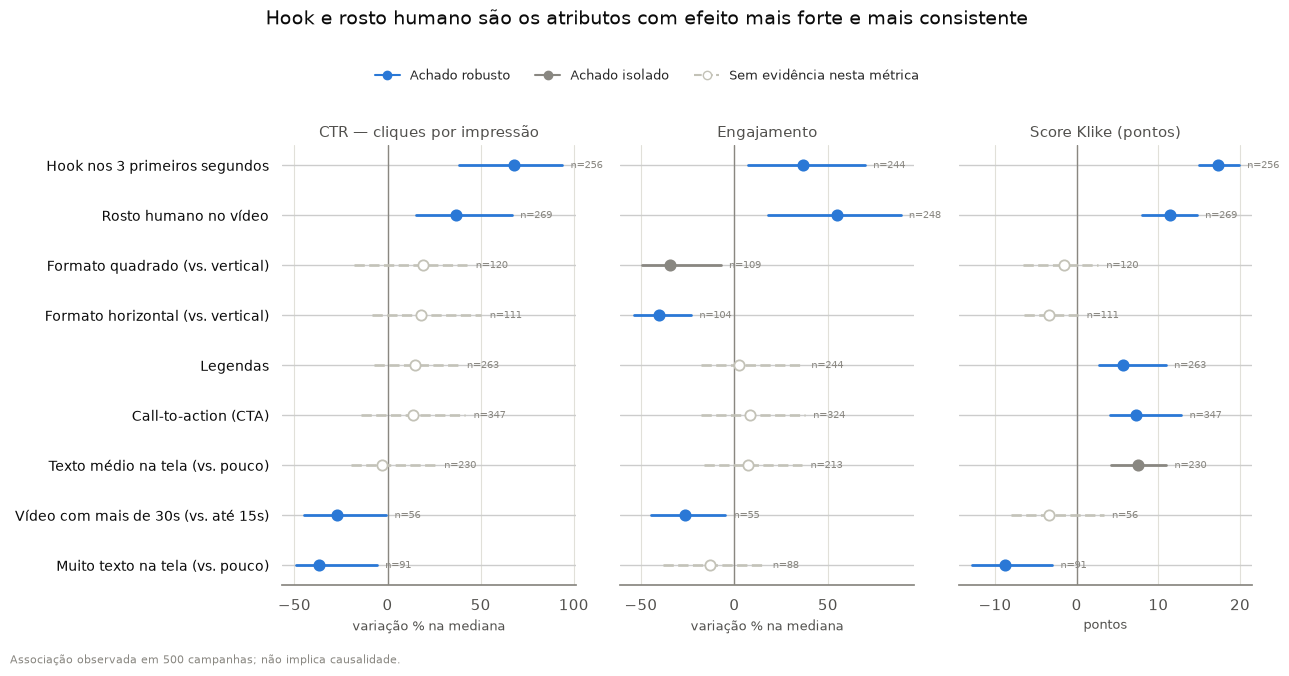

In [39]:
fig1 = viz.forest_plot_ctr_engajamento_score(tabela_geral, achados)
fig1.savefig(FIGURES_DIR / "forest_ctr_engajamento_score.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.2 Gráfico 2 — Heatmap atributo x plataforma (CTR)

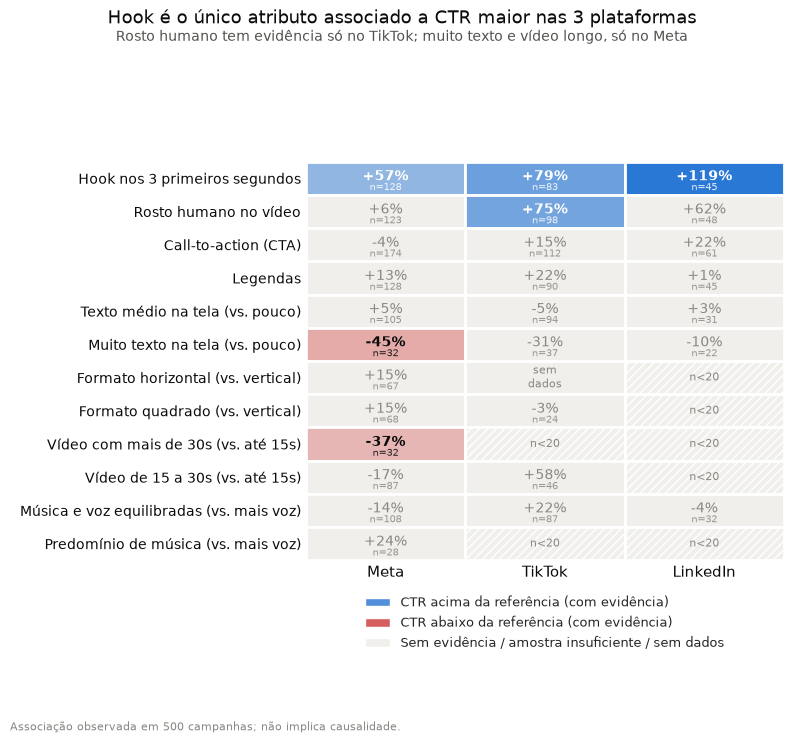

In [40]:
tabela_ctr_plataforma = tabela_plataforma[tabela_plataforma["metrica"] == "ctr"]
fig2 = viz.heatmap_ctr_plataforma(tabela_ctr_plataforma)
fig2.savefig(FIGURES_DIR / "heatmap_ctr_atributo_plataforma.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.3 Gráfico 3 — Score x performance (quintis)

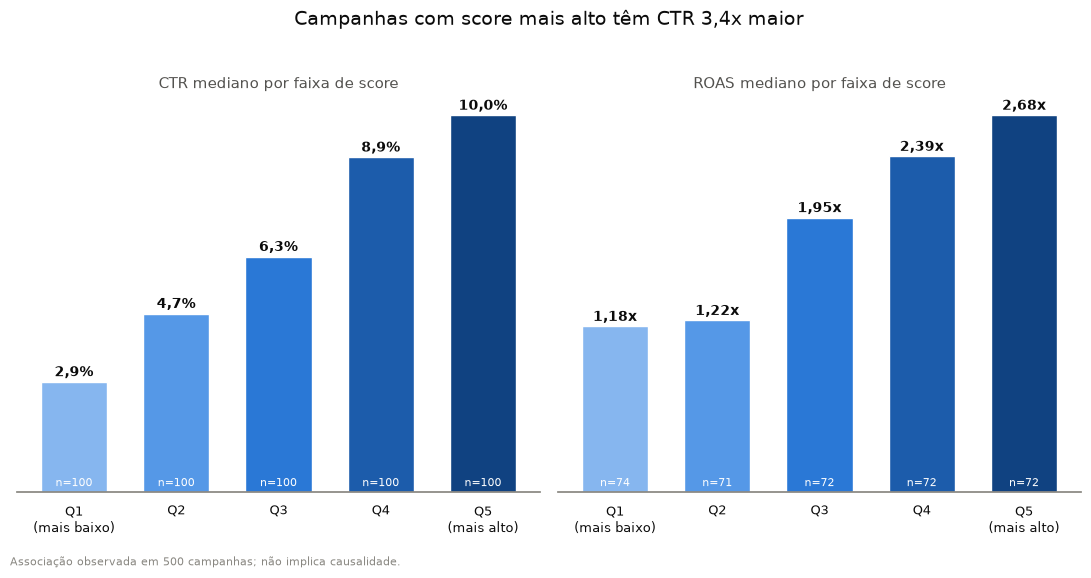

In [41]:
fig3 = viz.score_x_performance(df, df_roas)
fig3.savefig(FIGURES_DIR / "score_x_ctr_e_roas.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.4 Gráfico 4 — Checklist do criativo (`n_boas_praticas`)

`n_boas_praticas` = soma de `has_hook` + `has_face` + (`text_density` != "high") + (`video_duration_s` <= 30s) — só práticas com evidência de impacto em performance REAL (não inclui `has_cta`/`has_subtitle`, que só têm evidência em `klike_score`). Nova função reutilizável em `src/klike/features.py` (será usada na Parte 2).

In [42]:
df["n_boas_praticas"] = n_boas_praticas(df)

sem_duracao = df["video_duration_s"].isna()
print(f"linhas excluídas deste gráfico (video_duration_s nulo): {int(sem_duracao.sum())}")

base_checklist = df[~sem_duracao].copy()
base_checklist["faixa"] = (
    base_checklist["n_boas_praticas"].replace({0.0: "0-1", 1.0: "0-1"}).astype(str).str.replace(".0", "", regex=False)
)

ordem_faixas = ["0-1", "2", "3", "4"]
contagem_faixas = base_checklist["faixa"].value_counts()
print("\nn por faixa (0 e 1 já unidos por terem n<20 isoladamente):")
print(contagem_faixas.reindex(ordem_faixas))

linhas_resumo = []
for faixa in ordem_faixas:
    grupo = base_checklist.loc[base_checklist["faixa"] == faixa, "ctr"]
    linhas_resumo.append({"faixa": faixa, **eda.bootstrap_median_ci(grupo.to_numpy())})
resumo_faixas = pd.DataFrame(linhas_resumo)
resumo_faixas

linhas excluídas deste gráfico (video_duration_s nulo): 39

n por faixa (0 e 1 já unidos por terem n<20 isoladamente):
faixa
0-1     35
2      144
3      186
4       96
Name: count, dtype: int64


,faixa,n,mediana,ic_baixo,ic_alto
0,0-1,35,0.023617,0.020793,0.031347
1,2,144,0.051022,0.046597,0.066659
2,3,186,0.064208,0.054719,0.080021
3,4,96,0.091873,0.078841,0.108580


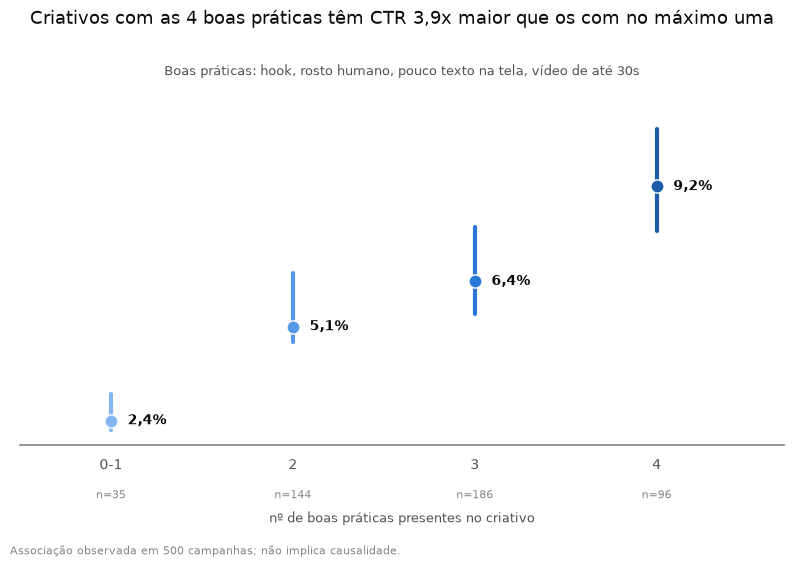

In [43]:
fig4 = viz.checklist_criativo(resumo_faixas)
fig4.savefig(FIGURES_DIR / "checklist_criativo_ctr.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.5 Gráfico de apoio (técnico) — mix de criativos por plataforma

Fica só no notebook técnico, não entra no README — apoia a leitura do item 11.6/11.9 (confundimento por mix de plataforma nos atributos `format` e `video_duration_bin`).

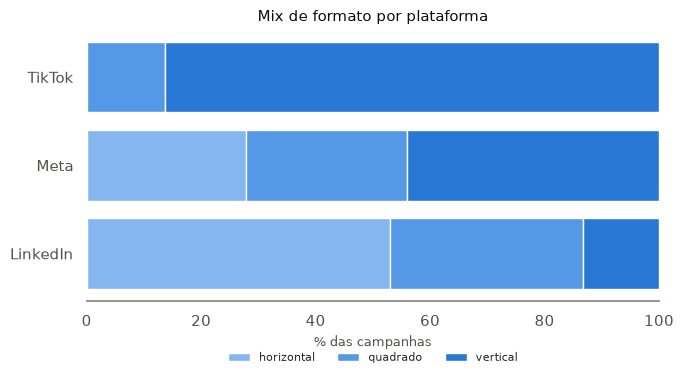

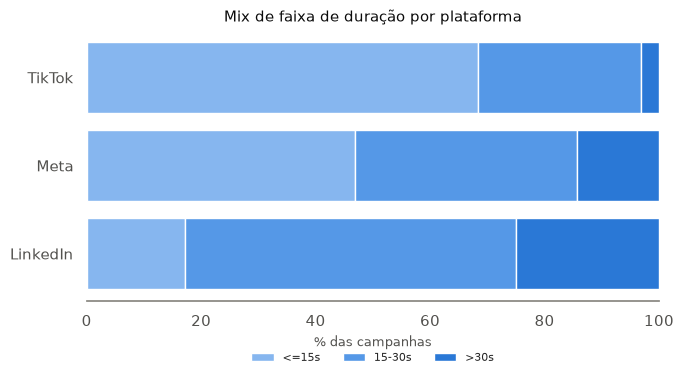

In [44]:
fig5a = viz.mix_por_plataforma(df, "format", "Mix de formato por plataforma")
fig5a.savefig(FIGURES_DIR / "mix_formato_por_plataforma.png", dpi=150, bbox_inches="tight")
plt.show()

fig5b = viz.mix_por_plataforma(df, "video_duration_bin", "Mix de faixa de duração por plataforma")
fig5b.savefig(FIGURES_DIR / "mix_duracao_por_plataforma.png", dpi=150, bbox_inches="tight")
plt.show()